# Praktikum 3 - Klasterisasi Berbasis Kepadatan (DBSCAN)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum ketiga di Jobsheet 4 ini saya mempelajari algoritma **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) menggunakan dataset sintetis 3 klaster dari `make_blobs`, menghitung estimasi jumlah klaster dan titik *noise* secara otomatis, mengevaluasi kualitas klaster dengan 6 metrik evaluasi, serta memvisualisasikan *core samples*, *non-core samples*, dan *noise*.

### Langkah 1 - Pembuatan Dataset Sintetis

Membuat dataset 750 titik dengan 3 pusat klaster menggunakan `make_blobs` dan menstandardisasi skalanya menggunakan `StandardScaler`.

In [1]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)
X = StandardScaler().fit_transform(X)

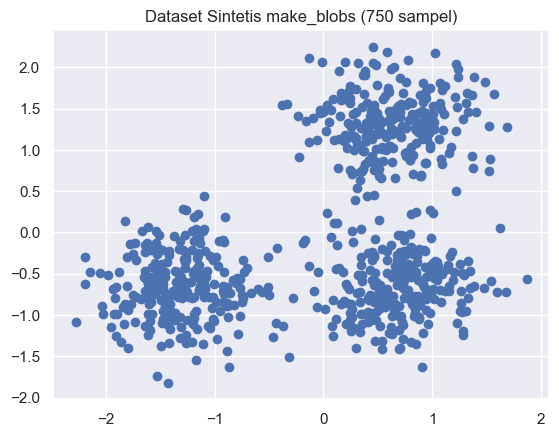

In [2]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.title('Dataset Sintetis make_blobs (750 sampel)')
plt.show()

### Langkah 2 - Compute DBSCAN

Menerapkan `DBSCAN` dengan parameter `eps=0.3` dan `min_samples=10`, lalu menghitung jumlah klaster yang terbentuk dan jumlah titik *noise* (label `-1`).

In [3]:
import numpy as np
from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


### Langkah 3 - Evaluasi Kualitas Klasterisasi

Menghitung metrik evaluasi klasterisasi (*Homogeneity*, *Completeness*, *V-measure*, *Adjusted Rand Index*, *Adjusted Mutual Information*, dan *Silhouette Coefficient*).

In [4]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


### Langkah 4 - Visualisasi Hasil Klasterisasi

Memvisualisasikan hasil DBSCAN di mana *core sample* digambarkan sebagai titik besar berwarna, *non-core sample* (border point) sebagai titik kecil berwarna, dan *noise* (outlier) sebagai titik hitam.

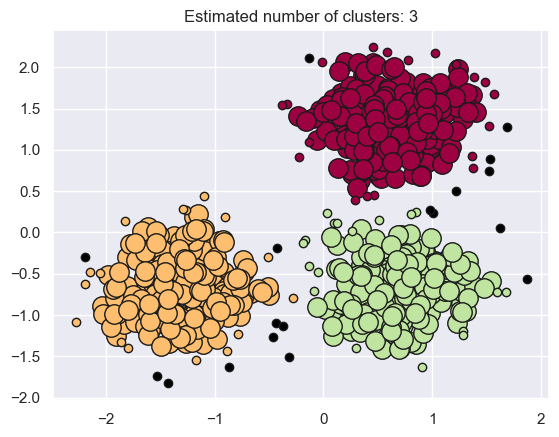

In [5]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

Dari hasil praktikum DBSCAN di atas, tanpa perlu menentukan jumlah klaster di awal, DBSCAN dengan `eps=0.3` dan `min_samples=10` secara otomatis menemukan **3 klaster** dan mengidentifikasi **18 titik *noise*** (ditandai warna hitam di pinggiran luar klaster). Nilai metrik evaluasinya juga sangat tinggi, yaitu *Homogeneity* `0.953`, *Completeness* `0.883`, *V-measure* `0.917`, *ARI* `0.952`, *AMI* `0.916`, dan *Silhouette Coefficient* `0.626`.